# Evaluación 3 – Modelado Predictivo de Riesgo Crediticio

## Fase 1: Diagnóstico y Calidad de Datos
En esta sección cargaremos el dataset `riesgo_crediticio.csv`, analizaremos la estructura general, calcularemos la presencia de nulos, revisaremos la consistencia de los datos, documentaremos el desbalance de la variable objetivo `Riesgo_Impago` y visualizaremos la distribución de las variables numéricas para detectar outliers.

In [ ]:
import os
import urllib.parse

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline

# 1. Cargar el dataset (URL de GitHub; si falla, se intenta el archivo local)
url_raw = 'https://raw.githubusercontent.com/chupetesuazo1/IA/refs/heads/main/E3-Clasificación/riesgo_crediticio.csv'
url = urllib.parse.quote(url_raw, safe=':/?=&#')

try:
    df = pd.read_csv(url)
except Exception as e:
    print(f"No se pudo leer la URL ({e}). Usando archivo local.")
    df = pd.read_csv('riesgo_crediticio.csv')

# Mostrar las primeras filas y estructura
print("--- Estructura General del Dataset ---")
display(df.head())
print(df.info())


--- Estructura General del Dataset ---


,Unnamed: 0,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,0,39785.55,85246.38,694.0,70.00,0
1,1,69773.95,244260.00,622.0,10.65,0
2,2,127770.68,209310.35,780.0,42.70,0
3,3,16799.80,213059.98,741.0,48.04,0
4,4,70229.83,219523.13,714.0,25.58,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              25000 non-null  int64  
 1   Ingreso_Anual           25000 non-null  float64
 2   Monto_Prestamo          25000 non-null  float64
 3   Puntaje_Credito         25000 non-null  float64
 4   Relacion_Deuda_Ingreso  25000 non-null  float64
 5   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 1.1 MB
None


In [ ]:
# Variable objetivo y semilla (mismo valor para modelos y GridSearchCV)
target = 'Riesgo_Impago'
RANDOM_STATE = 29

El dataset tiene 25.000 registros y 6 columnas, todas numéricas. La columna `Unnamed: 0` es solo el índice del archivo CSV, por lo que se eliminará en la Fase 2.

### Estadísticas descriptivas

In [ ]:
display(df.drop(columns='Unnamed: 0').describe().round(2))

,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
count,25000.00,25000.00,25000.00,25000.00,25000.00
mean,55824.44,220162.89,680.03,24.03,0.07
std,29804.90,60059.30,59.78,13.62,0.26
min,7832.12,50000.00,457.00,5.00,0.00
25%,35051.32,179438.08,640.00,13.79,0.00
50%,49234.68,220241.47,680.00,21.45,0.00
75%,68923.52,261003.36,721.00,31.38,0.00
max,348135.55,451784.21,850.00,70.00,1.00


Los rangos son coherentes con el negocio: ingresos entre \$US 7.800 y \$US 348.000, préstamos entre \$US 50.000 y \$US 452.000, puntaje de crédito entre 457 y 850, y una relación deuda/ingreso (DTI) entre 5% y 70%.

### 2. Calcular el porcentaje de valores nulos por cada variable

In [ ]:
null_percentage = (df.isnull().sum() / len(df)) * 100
null_summary = pd.DataFrame({
    'Valores Nulos': df.isnull().sum(),
    'Porcentaje (%)': null_percentage
}).sort_values(by='Porcentaje (%)', ascending=False)

print("--- Porcentaje de Valores Nulos ---")
display(null_summary)

--- Porcentaje de Valores Nulos ---


,Valores Nulos,Porcentaje (%)
Unnamed: 0,0,0.0
Ingreso_Anual,0,0.0
Monto_Prestamo,0,0.0
Puntaje_Credito,0,0.0
Relacion_Deuda_Ingreso,0,0.0
Riesgo_Impago,0,0.0


No hay valores nulos en ninguna variable.

##Consistencia según Reglas del Negocio

In [ ]:
print("=== CONSISTENCIA DE DATOS ===\n")

# Validación 1: Duplicados (se excluye el índice, que siempre es distinto)
print(f"Filas duplicadas: {df.drop(columns='Unnamed: 0').duplicated().sum()}\n")

# Validación 2: Reglas lógicas del diccionario de datos
reglas = {
    'Ingreso_Anual <= 0':               (df['Ingreso_Anual'] <= 0).sum(),
    'Monto_Prestamo <= 0':              (df['Monto_Prestamo'] <= 0).sum(),
    'Puntaje_Credito fuera de 300-850': ((df['Puntaje_Credito'] < 300) | (df['Puntaje_Credito'] > 850)).sum(),
    'Relacion_Deuda_Ingreso < 0':       (df['Relacion_Deuda_Ingreso'] < 0).sum(),
    'Relacion_Deuda_Ingreso > 100':     (df['Relacion_Deuda_Ingreso'] > 100).sum(),
    'Riesgo_Impago distinto de 0/1':    (~df['Riesgo_Impago'].isin([0, 1])).sum(),
}
for regla, n in reglas.items():
    print(f"{regla}: {n} registros")

# Validación 3: Valores repetidos justo en el límite y montos muy altos respecto al ingreso
print(f"\nRelacion_Deuda_Ingreso en su máximo ({df['Relacion_Deuda_Ingreso'].max()}): {(df['Relacion_Deuda_Ingreso'] == df['Relacion_Deuda_Ingreso'].max()).sum()} registros")
print(f"Préstamos que superan 10 veces el ingreso anual: {(df['Monto_Prestamo'] / df['Ingreso_Anual'] > 10).sum()} registros")

=== CONSISTENCIA DE DATOS ===

Filas duplicadas: 0

Ingreso_Anual <= 0: 0 registros
Monto_Prestamo <= 0: 0 registros
Puntaje_Credito fuera de 300-850: 0 registros
Relacion_Deuda_Ingreso < 0: 0 registros
Relacion_Deuda_Ingreso > 100: 0 registros
Riesgo_Impago distinto de 0/1: 0 registros

Relacion_Deuda_Ingreso en su máximo (70.0): 196 registros
Préstamos que superan 10 veces el ingreso anual: 1785 registros


No se encontraron inconsistencias lógicas: no hay ingresos ni montos menores o iguales a 0, los puntajes están dentro de 300-850 y la relación deuda/ingreso no supera 100%. Dos puntos a considerar:
* La relación deuda/ingreso parece estar truncada en 70 (196 clientes justo en ese valor).
* 1.785 préstamos superan 10 veces el ingreso anual. Son montos altos, pero posibles en hipotecas, por lo que no se consideran errores.

### Revisión de los límites y de la columna `Unnamed: 0`

In [ ]:
# Valores en los límites y su tasa de impago
for col, val in [('Relacion_Deuda_Ingreso', 70), ('Puntaje_Credito', 850)]:
    sub = df[df[col] == val]
    print(f"{col} == {val}: {len(sub)} clientes, tasa de impago = {sub[target].mean()*100:.1f}% (global = {df[target].mean()*100:.1f}%)")

# ¿Unnamed: 0 es solo un índice? Debe ser 0..n-1 y no estar relacionado con el target
es_indice = (df['Unnamed: 0'] == np.arange(len(df))).all()
print(f"\nUnnamed: 0 es una secuencia 0..n-1: {es_indice}")
print(f"Correlación de Unnamed: 0 con {target}: {df['Unnamed: 0'].corr(df[target]):.4f}")
print("Tasa de impago por quinto del archivo:", df.groupby(df['Unnamed: 0'] // 5000)[target].mean().round(4).tolist())

Relacion_Deuda_Ingreso == 70: 196 clientes, tasa de impago = 50.5% (global = 7.2%)
Puntaje_Credito == 850: 49 clientes, tasa de impago = 2.0% (global = 7.2%)

Unnamed: 0 es una secuencia 0..n-1: True
Correlación de Unnamed: 0 con Riesgo_Impago: -0.0059
Tasa de impago por quinto del archivo: [0.0716, 0.0716, 0.0746, 0.074, 0.066]


* Los 196 clientes con DTI = 70 tienen una tasa de impago de ~50%, frente a 7,16% global. El tope es entonces un valor "70 o más" y concentra a los clientes de mayor riesgo, así que no se debe eliminar ni imputar.
* `Unnamed: 0` es una secuencia 0..n-1 sin relación con el target (correlación ≈ 0), por lo que no hay fuga de información

### Análisis de la Variable Objetivo (Desbalance de Clases)
El contexto del negocio indica que la gran mayoría de los clientes paga sus deudas. Revisamos qué tan desbalanceada está `Riesgo_Impago`.

--- Distribución de Riesgo_Impago ---


,Clientes,Porcentaje (%)
Riesgo_Impago,,
0,23211,92.84
1,1789,7.16


Razón de desbalance: 13.0 clientes cumplidores por cada impago


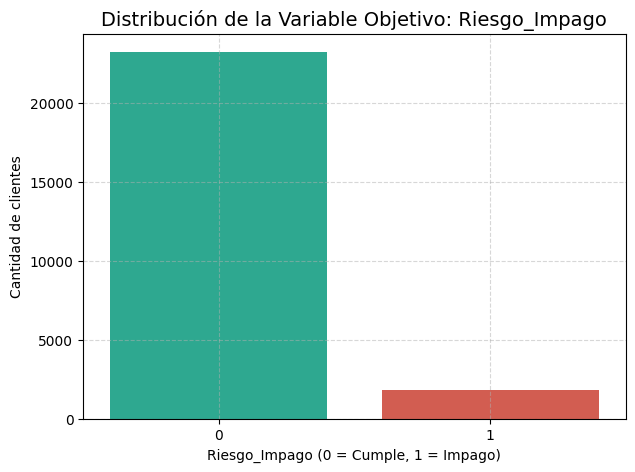

In [ ]:
conteo = df[target].value_counts()
porcentaje = df[target].value_counts(normalize=True) * 100

print("--- Distribución de Riesgo_Impago ---")
display(pd.DataFrame({'Clientes': conteo, 'Porcentaje (%)': porcentaje.round(2)}))
print(f"Razón de desbalance: {conteo[0] / conteo[1]:.1f} clientes cumplidores por cada impago")

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x=target, palette=['#1abc9c', '#e74c3c'], hue=target, legend=False)
plt.title('Distribución de la Variable Objetivo: Riesgo_Impago', fontsize=14)
plt.xlabel('Riesgo_Impago (0 = Cumple, 1 = Impago)')
plt.ylabel('Cantidad de clientes')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Observación:** la variable objetivo está fuertemente desbalanceada: 92,84% de los clientes cumple y solo 7,16% cae en impago (aprox. 13 a 1). Esto implica que:
* Un modelo que prediga "cumple" para todos tendría ~93% de *accuracy* sin detectar ningún impago, por lo que esa métrica no es adecuada.
* La división en entrenamiento y prueba debe estratificarse para mantener esta proporción en ambos conjuntos.

### Visualización de Outliers y Rangos con diagramas de caja para las variables numéricas

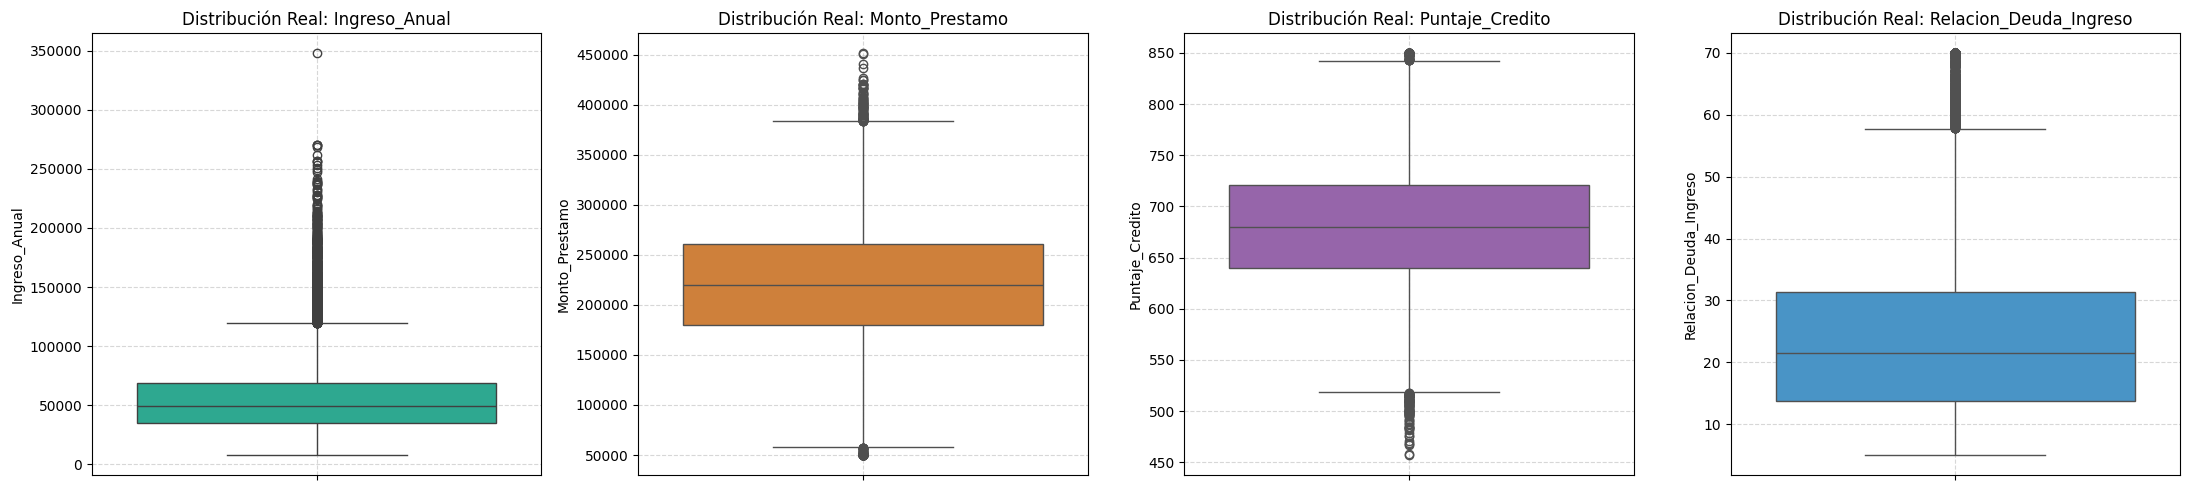

In [ ]:
variables = ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso']
colores = ['#1abc9c', '#e67e22', '#9b59b6', '#3498db']

fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(22, 5))

for ax, col, color in zip(axes, variables, colores):
    sns.boxplot(data=df, y=col, ax=ax, color=color)
    ax.set_title(f'Distribución Real: {col}')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Visualización de la Distribución de las Variables Numéricas

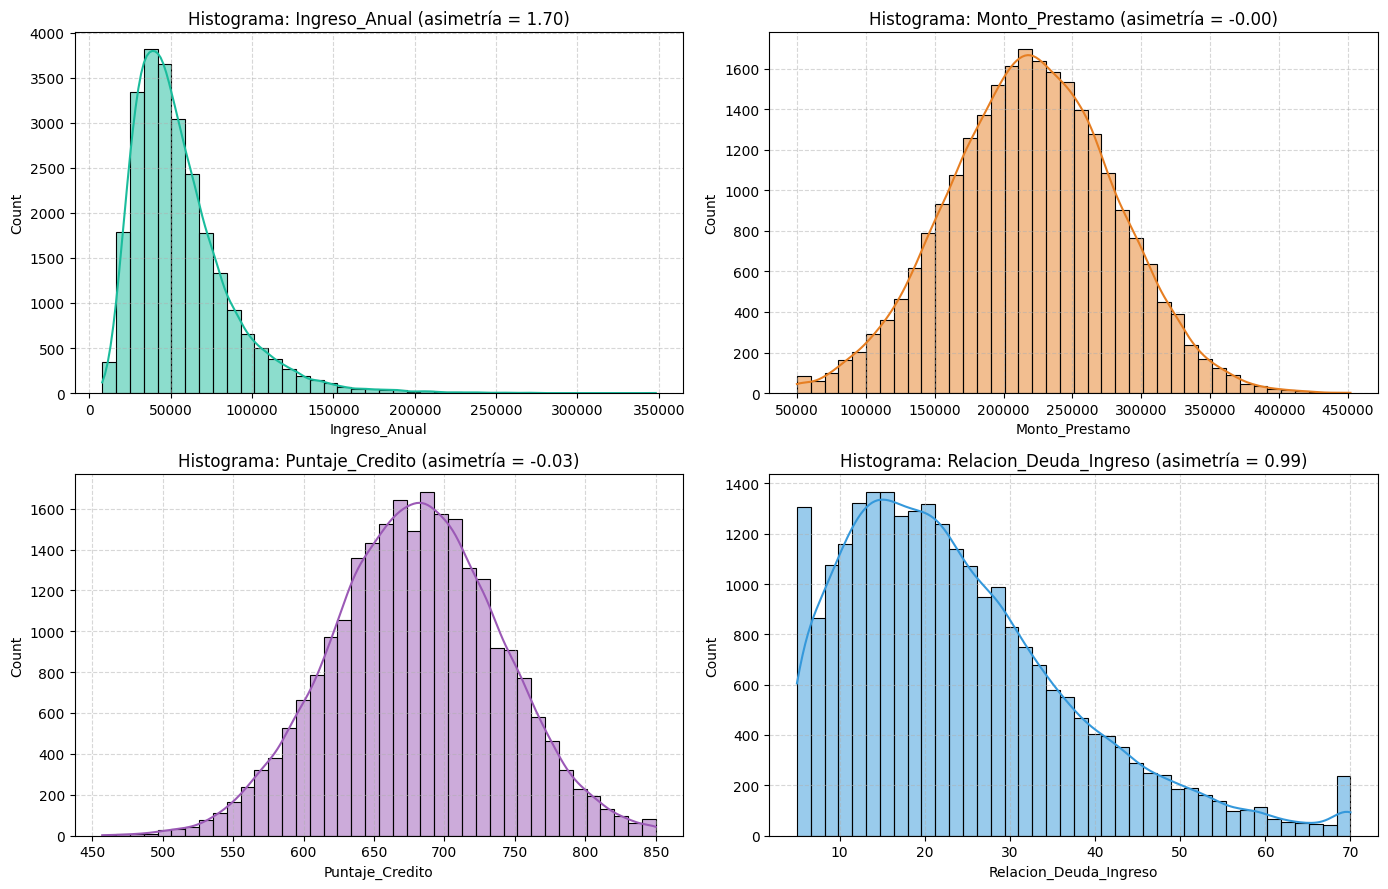

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 9))

for ax, col, color in zip(axes.flatten(), variables, colores):
    sns.histplot(data=df, x=col, bins=40, kde=True, ax=ax, color=color)
    ax.set_title(f'Histograma: {col} (asimetría = {df[col].skew():.2f})')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Detección Cuantitativa de Outliers (Valores Atípicos)

Para obtener un recuento exacto de los valores atípicos en cada variable numérica, utilizaremos el método del Rango Intercuartílico (IQR).

**Método IQR:**
1.  **Q1 (Primer Cuartil):** El 25% de los datos están por debajo de este valor.
2.  **Q3 (Tercer Cuartil):** El 75% de los datos están por debajo de este valor.
3.  **IQR (Rango Intercuartílico):** `IQR = Q3 - Q1`.
4.  **Límites para Outliers:**
    *   **Límite Inferior:** `Q1 - 1.5 * IQR`
    *   **Límite Superior:** `Q3 + 1.5 * IQR`

Cualquier valor por debajo del Límite Inferior o por encima del Límite Superior se considera un outlier.

In [ ]:
outliers_summary = {}
total_rows = len(df)

print("--- Conteo y Porcentaje de Valores Atípicos por Variable Numérica (Método IQR) ---")
for col in variables:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    num_outliers = len(outliers)
    percent_outliers = (num_outliers / total_rows) * 100

    outliers_summary[col] = {'Número de Outliers': num_outliers, 'Porcentaje (%)': percent_outliers}
    print(f"'{col}': {num_outliers} outliers ({percent_outliers:.2f}%)")

outliers_df = pd.DataFrame.from_dict(outliers_summary, orient='index')
display(outliers_df.sort_values(by='Número de Outliers', ascending=False))

--- Conteo y Porcentaje de Valores Atípicos por Variable Numérica (Método IQR) ---
'Ingreso_Anual': 976 outliers (3.90%)
'Monto_Prestamo': 157 outliers (0.63%)
'Puntaje_Credito': 167 outliers (0.67%)
'Relacion_Deuda_Ingreso': 663 outliers (2.65%)


,Número de Outliers,Porcentaje (%)
Ingreso_Anual,976,3.904
Relacion_Deuda_Ingreso,663,2.652
Puntaje_Credito,167,0.668
Monto_Prestamo,157,0.628


todas las variables tienen outliers, principalmente `Ingreso_Anual` (3,90%) y `Relacion_Deuda_Ingreso` (2,65%), ambas con cola hacia valores altos. Corresponden a clientes reales (ingresos muy altos o muy endeudados) y no a errores de registro, su tratamiento se definirá en la Fase 2.

### Relación de las Variables con el Riesgo de Impago
Para ver cuáles variables se asocian más al impago, calculamos la correlación con la variable objetivo y comparamos los promedios de cada variable según si el cliente cumple o no.

In [ ]:
print("--- Correlación con Riesgo_Impago ---")
display(df.drop(columns='Unnamed: 0').corr()[target].drop(target).sort_values(ascending=False).round(3))

print("--- Promedio de cada variable según Riesgo_Impago ---")
display(df.groupby(target)[variables].mean().round(2))

--- Correlación con Riesgo_Impago ---


,Riesgo_Impago
Relacion_Deuda_Ingreso,0.309
Monto_Prestamo,0.121
Ingreso_Anual,-0.113
Puntaje_Credito,-0.140


--- Promedio de cada variable según Riesgo_Impago ---


,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso
Riesgo_Impago,,,,
0,56757.46,218140.82,682.36,22.86
1,43719.24,246397.83,649.85,39.18


La variable más asociada al impago es `Relacion_Deuda_Ingreso` (0,31), seguida de `Puntaje_Credito` (-0,14), `Monto_Prestamo` (0,12) e `Ingreso_Anual` (-0,11). Las relaciones tienen sentido financiero (más endeudamiento, menor puntaje, mayor monto y menor ingreso se asocian a más impagos), aunque ninguna es muy fuerte.

### Resumen del Diagnóstico

| Aspecto | Hallazgo |
| --- | --- |
| Nulos | No hay |
| Tipos de dato | Todas numéricas |
| `Unnamed: 0` | Índice del CSV, sin valor predictivo |
| Inconsistencias lógicas | No hay. La relación deuda/ingreso está truncada en 70 (196 clientes, ~50 % de impago) |
| Duplicados | No hay |
| Outliers | Presentes en las 4 variables, valores plausibles |
| Variable objetivo | 92,84% / 7,16% (desbalance ~13:1) |

## Fase 2: Limpieza y Tratamiento de Datos

En esta fase prepararemos los datos para el modelado predictivo de acuerdo con las mejores prácticas y las pautas de la rúbrica:

1. **Separación de características ($X$) y variable objetivo ($y$)**, eliminando la columna redundante `Unnamed: 0` para evitar sesgos o almacenamiento innecesario.
2. **División Estratificada (Train/Test Split)** en una proporción 80/20, asegurando que la proporción de impagos (~7.16%) se mantenga aproximadamente igual en ambos conjuntos mediante `stratify=y` con la semilla establecida (`RANDOM_STATE = 29`).
3. **Definición de un Pipeline de Preprocesamiento** diferenciado:
   * **`RobustScaler`** para las variables con asimetría y outliers significativos (`Ingreso_Anual` y `Relacion_Deuda_Ingreso`).
   * **`StandardScaler`** para las variables con distribuciones más simétricas (`Monto_Prestamo` y `Puntaje_Credito`).


In [ ]:
# 1. Separación de características y variable objetivo (excluyendo el índice Unnamed: 0)
X = df.drop(columns=['Unnamed: 0', target])
y = df[target]

# 2. Partición del dataset de manera estratificada (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Dimensiones de X_train: {X_train.shape} | Proporción de clase: {y_train.mean():.4f}")
print(f"Dimensiones de X_test:  {X_test.shape}  | Proporción de clase: {y_test.mean():.4f}")
print("\n--- Distribución de clases tras la división estratificada ---")
display(pd.DataFrame({
    'Train (%)': y_train.value_counts(normalize=True).sort_index().mul(100).round(2),
    'Test (%)': y_test.value_counts(normalize=True).sort_index().mul(100).round(2)
}))

Dimensiones de X_train: (20000, 4) | Proporción de clase: 0.0716
Dimensiones de X_test:  (5000, 4)  | Proporción de clase: 0.0716

--- Distribución de clases tras la división estratificada ---


,Train (%),Test (%)
Riesgo_Impago,,
0,92.84,92.84
1,7.16,7.16


### Configuración del Pipeline de Preprocesamiento

Aplicamos transformaciones específicas según el análisis exploratorio previo (Fase 1) para evitar el impacto negativo de los valores atípicos sin perder sus registros.


In [ ]:
features_robust = ['Ingreso_Anual', 'Relacion_Deuda_Ingreso']
features_standard = ['Monto_Prestamo', 'Puntaje_Credito']

# Sub-pipelines: imputación + escalado, uno por tipo de variable
robust_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])
standard_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('robust', robust_pipe, features_robust),
        ('standard', standard_pipe, features_standard)
    ],
    remainder='drop',                 # las 4 variables predictoras están cubiertas
    verbose_feature_names_out=False
)
preprocessor.set_output(transform='pandas')   # conserva nombres de columnas e índice

# fit SOLO con train; test solo se transforma
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("--- Muestra de los Datos Preprocesados (Train) ---")
display(X_train_prep.head())
print("\n--- Estadísticas Descriptivas Post-Preprocesamiento (Train) ---")
display(X_train_prep.describe().round(3))

--- Muestra de los Datos Preprocesados (Train) ---


,Ingreso_Anual,Relacion_Deuda_Ingreso,Monto_Prestamo,Puntaje_Credito
22274,-0.513637,-0.501716,-0.665383,0.904828
11191,-0.664187,0.229405,-1.229609,-0.634882
18902,0.721951,-0.037757,-0.001768,1.021980
24192,0.508572,0.349542,-0.167368,-0.015651
2819,0.433616,0.185927,0.535779,-0.099331



--- Estadísticas Descriptivas Post-Preprocesamiento (Train) ---


,Ingreso_Anual,Relacion_Deuda_Ingreso,Monto_Prestamo,Puntaje_Credito
count,20000.000,20000.000,20000.000,20000.000
mean,0.193,0.146,-0.000,-0.000
std,0.875,0.777,1.000,1.000
min,-1.225,-0.941,-2.837,-3.731
25%,-0.419,-0.437,-0.679,-0.668
50%,0.000,0.000,-0.004,0.001
75%,0.581,0.563,0.678,0.671
max,6.538,2.777,3.864,2.846


## Fase 3: Construcción del Modelo: Entrenamiento y creación del modelo.

### 1. Modelo Base (Línea Base)
Entrenamos un `DecisionTreeClassifier` inicial con la configuración por defecto (fijando únicamente la semilla para consistencia) y medimos su rendimiento con la métrica ROC AUC en los conjuntos de entrenamiento y prueba.

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, auc, f1_score

# Crear el modelo base
modelo_base = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_STATE)

# Entrenar el modelo base con el set preprocesado
modelo_base.fit(X_train_prep, y_train)

# Predicciones de probabilidad para calcular ROC AUC
y_train_pred_prob_base = modelo_base.predict_proba(X_train_prep)[:, 1]
y_test_pred_prob_base = modelo_base.predict_proba(X_test_prep)[:, 1]

# Predicciones de clase para F1-score
y_train_pred_base = modelo_base.predict(X_train_prep)
y_test_pred_base = modelo_base.predict(X_test_prep)

# Evaluar ROC AUC
auc_train_base = roc_auc_score(y_train, y_train_pred_prob_base)
auc_test_base = roc_auc_score(y_test, y_test_pred_prob_base)

print("=== DESEMPEÑO MODELO BASE ===")
print(f"ROC-AUC Línea Base: {roc_auc_score(y_test, y_test_pred_prob_base):.4f}")
print("="*100)
print(f"ROC AUC Train: {auc_train_base:.4f}")
print(f"ROC AUC Test:  {auc_test_base:.4f}")
print("="*100)
print(f"F1-score línea base en train: {f1_score(y_train, y_train_pred_base):.4f}")
print(f"F1-score línea base en test: {f1_score(y_test, y_test_pred_base):.4f}")

=== DESEMPEÑO MODELO BASE ===
ROC-AUC Línea Base: 0.6298
ROC AUC Train: 1.0000
ROC AUC Test:  0.6298
F1-score línea base en train: 1.0000
F1-score línea base en test: 0.3060


### 2. Optimización de Hiperparámetros con GridSearchCV
Configuramos la búsqueda de grilla evaluando un espacio de 4 hiperparámetros críticos del árbol de decisión. Para contrarrestar el fuerte desbalance de clases (aproximadamente 13:1) y priorizar la viabilidad económica del negocio, optimizaremos los parámetros guiando la búsqueda directamente mediante nuestra métrica personalizada de **Costo Financiero Total**.


Para garantizar la consistencia entre la fase de entrenamiento y la fase de evaluación, configuraremos la búsqueda de hiperparámetros utilizando una métrica personalizada (*custom scorer*). En lugar de optimizar una métrica estándar y abstracta como ROC AUC, utilizaremos `make_scorer` para guiar a `GridSearchCV` a encontrar la estructura de árbol que **minimice directamente el Costo Financiero de la Entidad**, considerando los pesos asimétricos del negocio ($1.500.000 por FN y $200.000 por FP).

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, confusion_matrix

# Definir la función de costo financiero del negocio
def costo_financiero_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    costo = (fp * 200000) + (fn * 1500000)
    return costo

# 2. Convertir a scorer de sklearn (fijando greater_is_better=False para minimizar)
costo_scorer = make_scorer(costo_financiero_score, greater_is_better=False)

# 3. Crear el Pipeline que unifica preprocesamiento y clasificador
pipeline_optimo = Pipeline([
    ('preprocessor', preprocessor),
    ('tree', DecisionTreeClassifier(random_state=RANDOM_STATE))
])

# 4. Definir la grilla de parámetros usando el prefijo 'tree__'
param_grid_gini = {
    'tree__max_depth': [3, 5, 7, 10],
    'tree__min_samples_split': [2, 5, 10],
    'tree__min_samples_leaf': [1, 2, 4, 8],
    'tree__class_weight': [None, 'balanced']
}

# 5. Configurar GridSearchCV de forma metodológicamente blindada
grid_search_gini = GridSearchCV(
    estimator=pipeline_optimo,
    param_grid=param_grid_gini,
    scoring=costo_scorer,
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Entrenar directamente sobre los datos de entrenamiento crudos (X_train) sin preparar por fuera
grid_search_gini.fit(X_train, y_train)

# Obtener el mejor pipeline
pipeline_final = grid_search_gini.best_estimator_
modelo_optimo = pipeline_final.named_steps['tree']

print(f"\nMejores parámetros optimizando costo financiero (sin data leakage):\n{grid_search_gini.best_params_}")
print("="*100)
print(f"Mejor costo promedio en validación cruzada: ${abs(grid_search_gini.best_score_):,.0f}")

Fitting 5 folds for each of 96 candidates, totalling 480 fits

Mejores parámetros optimizando costo financiero (sin data leakage):
{'tree__class_weight': 'balanced', 'tree__max_depth': 5, 'tree__min_samples_leaf': 1, 'tree__min_samples_split': 2}
Mejor costo promedio en validación cruzada: $295,020,000


### 3. Visualización del Árbol de Decisión Optimizado
Graficamos el árbol optimizado usando `plot_tree` para comprender el flujo de las reglas de decisión.

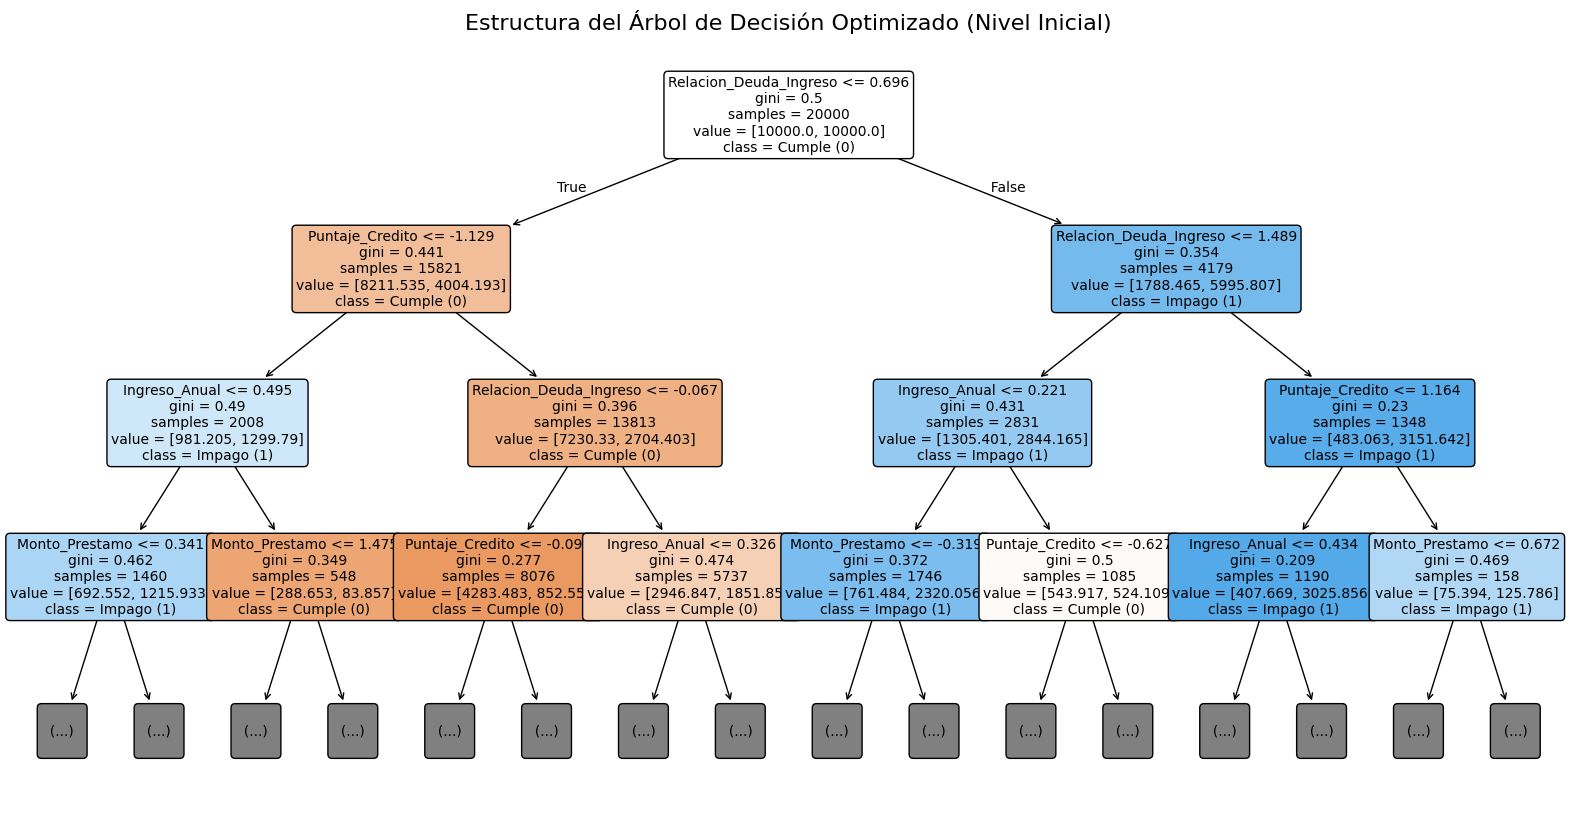

=== REGLAS DE DECISIÓN DEL ÁRBOL OPTIMIZADO ===
|--- Relacion_Deuda_Ingreso <= 0.70
|   |--- Puntaje_Credito <= -1.13
|   |   |--- Ingreso_Anual <= 0.50
|   |   |   |--- Monto_Prestamo <= 0.34
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Monto_Prestamo >  0.34
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Ingreso_Anual >  0.50
|   |   |   |--- Monto_Prestamo <= 1.48
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Monto_Prestamo >  1.48
|   |   |   |   |--- truncated branch of depth 2
|   |--- Puntaje_Credito >  -1.13
|   |   |--- Relacion_Deuda_Ingreso <= -0.07
|   |   |   |--- Puntaje_Credito <= -0.09
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Puntaje_Credito >  -0.09
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Relacion_Deuda_Ingreso >  -0.07
|   |   |   |--- Ingreso_Anual <= 0.33
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Ingreso_Anual >  0.33
|   |   |   |   |--- tr

In [ ]:
from sklearn.tree import export_text

# 1. Graficar el árbol de decisión
plt.figure(figsize=(20, 10))
plot_tree(
    modelo_optimo,
    max_depth=3, # Limitamos la profundidad de visualización para legibilidad
    feature_names=X_train_prep.columns.tolist(),
    class_names=['Cumple (0)', 'Impago (1)'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Estructura del Árbol de Decisión Optimizado (Nivel Inicial)", fontsize=16)
plt.show()

# 2. Exportar e imprimir las reglas lógicas del árbol en texto plano
print("=== REGLAS DE DECISIÓN DEL ÁRBOL OPTIMIZADO ===")
reglas_texto = export_text(modelo_optimo, feature_names=X_train_prep.columns.tolist(), max_depth=3)
print(reglas_texto)

### 4. Evaluación Comparativa del Desempeño (Modelo Base vs Modelo Optimizado)
Comparamos el desempeño en los sets de Train y Test mediante reportes de clasificación detallados y el trazado de las curvas ROC.

=== REPORTE DE CLASIFICACIÓN (TEST) - MODELO BASE ===
              precision    recall  f1-score   support

           0       0.95      0.94      0.94      4642
           1       0.29      0.32      0.31       358

    accuracy                           0.90      5000
   macro avg       0.62      0.63      0.63      5000
weighted avg       0.90      0.90      0.90      5000

=== REPORTE DE CLASIFICACIÓN (TEST) - MODELO OPTIMIZADO ===
              precision    recall  f1-score   support

           0       0.98      0.72      0.83      4642
           1       0.17      0.77      0.28       358

    accuracy                           0.72      5000
   macro avg       0.57      0.74      0.56      5000
weighted avg       0.92      0.72      0.79      5000



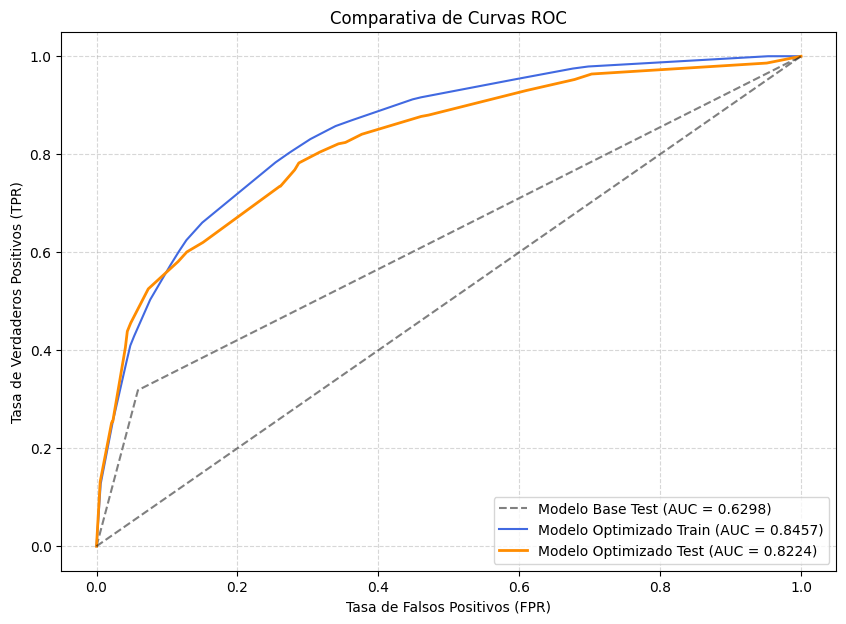

In [ ]:
# Predicciones con el pipeline optimizado final (preprocesamiento + árbol de decisión)
y_train_pred_opt = pipeline_final.predict(X_train)
y_test_pred_opt = pipeline_final.predict(X_test)

y_train_pred_prob_opt = pipeline_final.predict_proba(X_train)[:, 1]
y_test_pred_prob_opt = pipeline_final.predict_proba(X_test)[:, 1]

# Reportes de clasificación
print("=== REPORTE DE CLASIFICACIÓN (TEST) - MODELO BASE ===")
print(classification_report(y_test, modelo_base.predict(X_test_prep)))

print("=== REPORTE DE CLASIFICACIÓN (TEST) - MODELO OPTIMIZADO ===")
print(classification_report(y_test, y_test_pred_opt))

# Calcular curvas ROC
fpr_base_test, tpr_base_test, _ = roc_curve(y_test, y_test_pred_prob_base)
auc_base_test = auc(fpr_base_test, tpr_base_test)

fpr_opt_train, tpr_opt_train, _ = roc_curve(y_train, y_train_pred_prob_opt)
auc_opt_train = auc(fpr_opt_train, tpr_opt_train)

fpr_opt_test, tpr_opt_test, _ = roc_curve(y_test, y_test_pred_prob_opt)
auc_opt_test = auc(fpr_opt_test, tpr_opt_test)

# Graficar curvas ROC
plt.figure(figsize=(10, 7))
plt.plot(fpr_base_test, tpr_base_test, label=f'Modelo Base Test (AUC = {auc_base_test:.4f})', color='grey', linestyle='--')
plt.plot(fpr_opt_train, tpr_opt_train, label=f'Modelo Optimizado Train (AUC = {auc_opt_train:.4f})', color='royalblue')
plt.plot(fpr_opt_test, tpr_opt_test, label=f'Modelo Optimizado Test (AUC = {auc_opt_test:.4f})', color='darkorange', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Comparativa de Curvas ROC')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 5. Análisis de Matrices de Confusión
Graficamos las matrices de confusión de forma independiente para analizar a fondo la distribución de falsos positivos y, sobre todo, de falsos negativos (impagos no detectados).

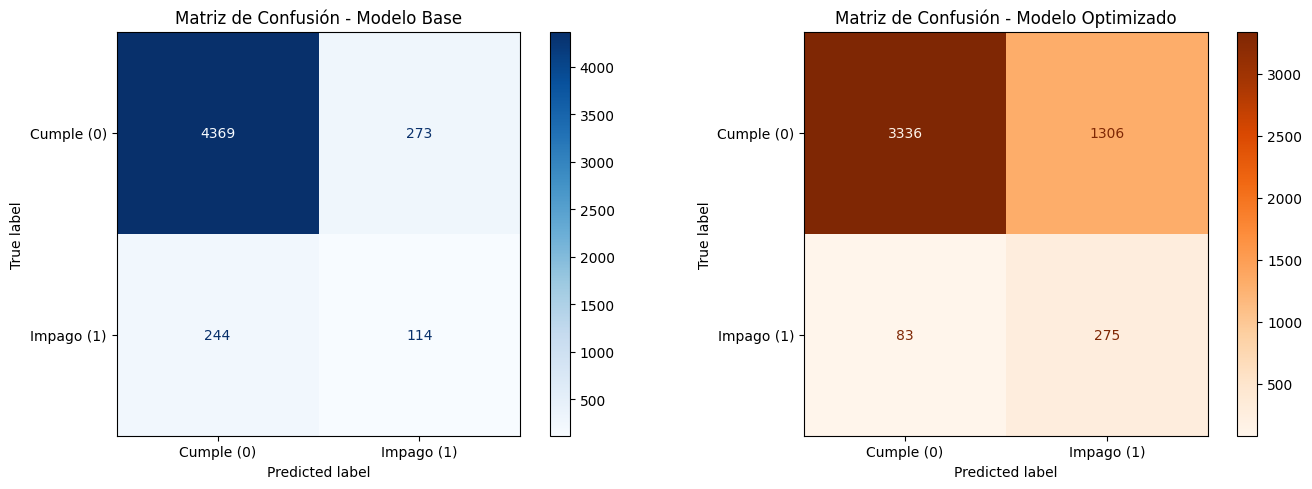

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Crear la figura para comparar las matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusión - Modelo Base
cm_base = confusion_matrix(y_test, modelo_base.predict(X_test_prep))
disp_base = ConfusionMatrixDisplay(confusion_matrix=cm_base, display_labels=['Cumple (0)', 'Impago (1)'])
disp_base.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title("Matriz de Confusión - Modelo Base", fontsize=12)

# Matriz de Confusión - Modelo Optimizado
cm_opt = confusion_matrix(y_test, y_test_pred_opt)
disp_opt = ConfusionMatrixDisplay(confusion_matrix=cm_opt, display_labels=['Cumple (0)', 'Impago (1)'])
disp_opt.plot(ax=axes[1], cmap='Oranges', values_format='d')
axes[1].set_title("Matriz de Confusión - Modelo Optimizado", fontsize=12)

plt.tight_layout()
plt.show()

## Fase 4: Evaluación e Interpretación de Métricas: Validación en el conjunto de prueba.


### Selección y Justificación de Métricas de Desempeño

Para validar el comportamiento de nuestros modelos en el conjunto de prueba, seleccionamos **dos métricas clave** fundamentadas en la naturaleza de los datos y en los objetivos estratégicos de la institución financiera:

1. **Recall (Sensibilidad) - Métrica Estándar:**
   * **Por qué no utilizamos *Accuracy* (Exactitud):** Como se diagnosticó en la Fase 1, el dataset presenta un severo desbalance de clases de aproximadamente 13:1 (92.84% de clientes cumplidores vs. 7.16% en impago). En este escenario, un modelo ingenuo o perezoso que clasifique a todos los clientes como "cumplidores" (clase 0) obtendría un *Accuracy* sobresaliente del 92.84% sin llegar a detectar un solo caso de mora. Por lo tanto, la exactitud es una métrica engañosa e inviable para este problema de negocio.
   * **Justificación de Recall:** El riesgo crítico de la entidad radica en los **Falsos Negativos (FN)**; es decir, catalogar como solvente a un cliente que terminará incumpliendo. El Recall mide la proporción de casos de impago reales que el modelo es capaz de identificar de forma proactiva. Maximizar el Recall reduce directamente la cantidad de créditos fallidos otorgados.

2. **Costo Financiero Total - Métrica Ad-hoc de Negocio (Complementada con Precisión):**
   * **Justificación de la Métrica Propia:** En el ámbito de la evaluación crediticia, los errores de clasificación no son simétricos. Un Falso Negativo (otorgar un crédito incobrable) tiene un costo severo de **$1.500.000**, mientras que un Falso Positivo (rechazar a un cliente solvente) representa un costo de oportunidad de colocación estimado en **$200.000** (pérdida de captación por intereses). Evaluamos el desempeño financiero ponderando explícitamente ambos errores mediante la fórmula:
     $$\text{Costo Financiero} = (FP \times \$200.000) + (FN \times \$1.500.000)$$
   * **Complemento con Precisión:** Aunque el Costo Financiero es nuestra métrica rectora de negocio, la complementamos técnicamente con el análisis de la **Precisión** de la clase 1 (impago). Esto nos permite monitorear el impacto colateral de la tasa de rechazo sobre clientes viables, asegurando que la búsqueda de seguridad financiera no asfixie la colocación comercial de la entidad.

In [ ]:
from sklearn.metrics import recall_score, confusion_matrix

# Obtener predicciones de ambos modelos en el conjunto de prueba de manera coherente
y_pred_base = modelo_base.predict(X_test_prep)
y_pred_opt = pipeline_final.predict(X_test)

# Función unificada para calcular indicadores métricos y costos financieros
def obtener_resultados(nombre, y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    recall = recall_score(y_real, y_pred, pos_label=1) * 100

    costo_fp = fp * 200000
    costo_fn = fn * 1500000
    costo_total = costo_fp + costo_fn

    return {
        "Modelo": nombre,
        "Recall (%)": recall,
        "Verdaderos negativos (VN)": tn,
        "Falsos positivos (FP)": fp,
        "Falsos negativos (FN)": fn,
        "Verdaderos positivos (VP)": tp,
        "Costo por falsos positivos ($)": costo_fp,
        "Costo por falsos negativos ($)": costo_fn,
        "Costo financiero total ($)": costo_total
    }

# Evaluar de manera unificada ambos modelos
res_base = obtener_resultados("Modelo Base", y_test, y_pred_base)
res_opt = obtener_resultados("Modelo Optimizado", y_test, y_pred_opt)

print(f"--- Modelo Base ---\nRecall: {res_base['Recall (%)']:.2f}%\nCosto financiero: ${res_base['Costo financiero total ($)']:,.0f}")
print(f"\n--- Modelo Optimizado ---\nRecall: {res_opt['Recall (%)']:.2f}%\nCosto financiero: ${res_opt['Costo financiero total ($)']:,.0f}")

--- Modelo Base ---
Recall: 31.84%
Costo financiero: $420,600,000

--- Modelo Optimizado ---
Recall: 76.82%
Costo financiero: $385,700,000


### Interpretación de la matriz de confusión

In [ ]:
# Crear tabla comparativa consolidada a partir de los resultados unificados
comparacion = pd.DataFrame({
    "Indicador": [k for k in res_base.keys() if k != "Modelo"],
    "Modelo Base": [res_base[k] for k in res_base.keys() if k != "Modelo"],
    "Modelo Optimizado": [res_opt[k] for k in res_base.keys() if k != "Modelo"]
})

# Calcular la diferencia absoluta (Optimizado - Base)
comparacion["Diferencia"] = comparacion["Modelo Optimizado"] - comparacion["Modelo Base"]

# Formatear la tabla comparativa para su presentación formal
for columna in ["Modelo Base", "Modelo Optimizado", "Diferencia"]:
    comparacion[columna] = [
        f"{valor:.2f}%" if indicador == "Recall (%)"
        else f"${valor:,.0f}" if "$" in indicador
        else f"{valor:,.0f}"
        for indicador, valor in zip(comparacion["Indicador"], comparacion[columna])
    ]

display(comparacion)

,Indicador,Modelo Base,Modelo Optimizado,Diferencia
0,Recall (%),31.84%,76.82%,44.97%
1,Verdaderos negativos (VN),"4,369","3,336","-1,033"
2,Falsos positivos (FP),273,"1,306","1,033"
3,Falsos negativos (FN),244,83,-161
4,Verdaderos positivos (VP),114,275,161
5,Costo por falsos positivos ($),"$54,600,000","$261,200,000","$206,600,000"
6,Costo por falsos negativos ($),"$366,000,000","$124,500,000","$-241,500,000"
7,Costo financiero total ($),"$420,600,000","$385,700,000","$-34,900,000"


### Interpretación de Resultados en el Contexto de Negocio Financiero

*   **Análisis del Modelo Base (Línea Base):**
    Este modelo se caracteriza por una postura sumamente conservadora al clasificar impagos debido al desbalance original de los datos. En términos de negocio, de los 5.000 clientes evaluados en el conjunto de prueba, el modelo genera **4.369 Verdaderos Negativos (VN)**, que representan clientes solventes correctamente identificados a quienes se les otorga el crédito de manera segura. Sin embargo, genera apenas **114 Verdaderos Positivos (VP)** (impagos correctamente detectados y evitados) frente a un alarmante número de **244 Falsos Negativos (FN)**. Un FN en este contexto significa otorgar un crédito a un cliente que finalmente incurrirá en mora, costándole a la entidad $1.500.000 por cada ocurrencia. Esto resulta en una pérdida catastrófica por asunción de riesgo de **$366.000.000** (244 * $1.500.000). A su vez, genera **273 Falsos Positivos (FP)**, que son clientes sanos rechazados erróneamente, provocando un costo de oportunidad (pérdida de captación de intereses) de **$54.600.000** (273 * $200.000). El costo financiero total de este modelo asciende a **$420.600.000** debido a su severa incapacidad para detectar el riesgo (Recall de solo **31,84%**).

*   **Análisis del Modelo Optimizado:**
    Al ajustar los hiperparámetros e incorporar pesos balanceados de clase (`class_weight='balanced'`), el modelo prioriza de forma agresiva la detección de perfiles de riesgo. Esto se traduce en **275 Verdaderos Positivos (VP)** (impagos prevenidos) y reduce drásticamente los **Falsos Negativos (FN) a solo 83**. Esta mejora mitiga de forma contundente la pérdida por impagos imprevistos, reduciendo este costo a **$124.500.000** (83 * $1.500.000). Por otra parte, para lograr este nivel de protección, el modelo disminuye los **Verdaderos Negativos (VN) a 3.336** e incrementa sustancialmente los **Falsos Positivos (FP) a 1.306** (clientes solventes rechazados por sospecha de riesgo), lo que eleva el costo de oportunidad por colocación perdida a **$261.200.000** (1.306 * $200.000). El costo financiero total bajo este esquema de control estricto se sitúa en **$385.700.000**, respaldado por un Recall óptimo del **76,82%**.

*   **Comparativa y Balance de Decisiones:**
    Al contrastar ambos modelos, se hace evidente el compromiso financiero (*trade-off*) entre el riesgo de impago y el costo de oportunidad. El Modelo Optimizado acepta asumir un incremento del 378% en el costo por colocaciones perdidas (de $54.600.000 a $261.200.000 en FP) a cambio de reducir un 66% el costo por pérdidas directas de cartera vencida (de $366.000.000 a $124.500.000 en FN). Financieramente, esta estrategia es plenamente rentable: la mitigación de los créditos incobrables supera con creces el costo del rechazo de clientes aptos, generando un **ahorro neto absoluto de $34.900.000** para la institución financiera. Por lo tanto, el modelo optimizado es la opción técnica y económicamente viable para la gestión del riesgo.

## Resumen Ejecutivo de Resultados y Decisiones de Negocio

A continuación, se presenta un resumen consolidado del impacto estratégico tras la implementación del **Modelo de Árbol de Decisión Optimizado por Costos** frente a la línea base:

### 📊 Tabla Comparativa de Desempeño

| Indicador / Métrica | Modelo Base (Línea Base) | Modelo Optimizado (Costo) | Impacto / Variación |
| :--- | :---: | :---: | :---: |
| **Tasa de detección de impagos (Recall)** | 31,84% | **76,82%** | **+44,98 pp** (Mejora Crítica) |
| **Verdaderos Negativos (VN)** | 4.369 | 3.336 | -1.033 clientes solventes |
| **Falsos Positivos (FP)** *(Rechazo erróneo)* | 273 | 1.306 | +1.033 oportunidades perdidas |
| **Falsos Negativos (FN)** *(Mora imprevista)* | 244 | **83** | **-161 créditos fallidos evitados** |
| **Costo por Falsos Positivos (FP)** | $54.600.000 | $261.200.000 | +$206.600.000 (Costo comercial) |
| **Costo por Falsos Negativos (FN)** | $366.000.000 | $124.500.000 | -$241.500.000 (Ahorro en cartera vencida) |
| **Costo Financiero Total** | **$420.600.000** | **$385.700.000** | **Ahorro Neto: $34.900.000** |

---

### 🔑 Conclusiones Estratégicas y de Negocio

1. **Reducción Drástica del Riesgo Catastrófico:**
   El mayor peligro para la institución radica en el impago de deudas (Falsos Negativos), el cual genera una pérdida de **$1.500.000 por evento**. El modelo optimizado redujo estos casos de **244 a solo 83**, disminuyendo la pérdida de cartera vencida en un **66%** (un ahorro bruto de **$241.500.000**).

2. **Aceptación de Costo de Oportunidad Comercial:**
   Para lograr este blindaje, el modelo se volvió más estricto, aumentando los Falsos Positivos (clientes sanos rechazados) de **273 a 1.306**. Esto incrementó el costo de oportunidad de colocación en un **378%** ($206.600.000 adicionales no captados por intereses).

3. **Retorno de Inversión y Análisis de Sensibilidad (Ahorro Neto Efectivo):**
   Aunque la equivalencia teórica de costos del negocio dicta que **cada impago evitado compensa financieramente hasta 7,5 rechazos** de clientes aptos ($1.500.000 / $200.000), en la práctica del modelo óptimo se terminaron rechazando **6,4 clientes solventes adicionales por cada crédito en mora prevenido** (1.033 FP adicionales frente a 161 FN evitados). Al encontrarse operativamente por debajo del límite de equivalencia financiera, el retorno resulta positivo, consolidando un **ahorro neto real de $34.900.000** (una disminución del **8,3%** en las pérdidas globales frente al modelo base).